# River Water Quality Prediction — demonstration

**A small proof of concept using 100 real matched observations from three Ganga stations.**

The main model estimates **BOD in mg/L from satellite readings**. BOD describes oxygen used while microorganisms break down organic matter. It is one water-quality measurement, not an overall cleanliness or drinking-water safety score.

This notebook shows: matching → predictions → fair model comparison → feature selection → SHAP explanations → experimental gate, constraint and station-adversarial results.

**Presentation:** saved outputs and charts are included. Scroll through them to present immediately. To rerun in VS Code, install `requirements-notebook.txt`, select Python from `.venv-check` (or your environment), and click **Run All**. It restores missing demo files safely, performs a saved-model prediction, and reads saved experiment results. No training, satellite downloads, Google login or GPU is needed.

The existing predictor stays preserved. Experimental combined models require ground readings; they are separate from satellite-only prediction.


In [2]:
from pathlib import Path
import sys
import json
import hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'pyproject.toml').exists() and (p / 'demo_bundle').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from within the project repository.')
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'src'))
from scripts.restore_demo_bundle import restore

count = restore(ROOT / 'demo_bundle', ROOT)
print(f'Verified {count} bundled files; restored only missing identical demo files.')
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 3)

DATA = ROOT / 'outputs/india_100_chemical_dataset_20261014'
DEMOS = ROOT / 'outputs/straightforward_demos_20261014'
EXPERIMENT = ROOT / 'outputs/experimental_network_20261014'
def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))
def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()
model_paths = [ROOT / 'outputs/satellite_only_80_20_20261014/model.joblib',
               ROOT / 'outputs/fusion_sklearn_expanded_20261014/fusion_model.joblib']
original_model_hashes = {str(p.relative_to(ROOT)): sha(p) for p in model_paths}


Verified 143 bundled files; restored only missing identical demo files.


## 1. Real satellite–ground matches

Each row joins a CPCB sampling event with a nearby Sentinel-2 acquisition. Images must pass the existing cloud, coverage and usable-water-pixel checks. Ground chemical readings are matched by the recorded station name, date and coordinates.

**Inputs available:** ten satellite bands, fecal coliform, pH and dissolved oxygen. **Answer to predict:** measured BOD. Never give the BOD answer to the model as an input.


In [3]:
paired = pd.read_csv(DATA / 'paired.csv')
provenance = read_json(DATA / 'provenance.json')
assert sha(DATA / 'paired.csv') == provenance['output_sha256']
assert len(paired) == 100 and paired.observation_id.is_unique
station_labels = {
    'cpcb-0ecd9698ec1a2eb1': 'Anupshahar',
    'cpcb-1c6a3feabae131a4': 'Varanasi',
    'cpcb-baa51b840df3bdc2': 'Bijnor',
}
display(paired.groupby('station_id').size().rename('Matched events').rename(index=station_labels).to_frame())
matching = paired.copy()
matching['Station'] = matching.station_id.map(station_labels)
display(matching[['Station', 'sample_date', 'satellite_local_date', 'temporal_offset_days',
                  'cloud_fraction', 'water_fraction', 'ground_bod', 'ground_fecal_coliform',
                  'ground_ph', 'ground_dissolved_oxygen']].head(9))
print('100 complete pH/DO matches; exact source records are retained in chemical_audit.csv.')


,Matched events
station_id,
Anupshahar,38
Varanasi,37
Bijnor,25


,Station,sample_date,satellite_local_date,temporal_offset_days,cloud_fraction,water_fraction,ground_bod,ground_fecal_coliform,ground_ph,ground_dissolved_oxygen
0,Anupshahar,2018-11-25,2018-11-26,1,0.0,1.000,2.8,310.0,7.4,9.8
1,Anupshahar,2018-12-08,2018-12-08,0,0.0,1.000,2.6,250.0,7.5,9.7
2,Anupshahar,2019-01-14,2019-01-12,-2,0.0,1.000,2.4,230.0,7.4,10.4
3,Anupshahar,2019-02-07,2019-02-09,2,0.0,0.667,1.5,280.0,7.2,9.5
4,Anupshahar,2019-03-04,2019-03-06,2,0.0,0.633,1.2,250.0,7.3,9.9
5,Anupshahar,2019-06-20,2019-06-21,1,0.0,0.700,2.3,220.0,7.5,8.0
6,Anupshahar,2019-07-25,2019-07-21,-4,0.2,0.800,1.1,280.0,7.2,8.5
7,Anupshahar,2019-09-16,2019-09-17,1,0.0,1.000,1.3,240.0,7.1,7.4
8,Anupshahar,2019-10-10,2019-10-09,-1,0.0,0.800,2.0,240.0,7.2,7.6


100 complete pH/DO matches; exact source records are retained in chemical_audit.csv.


## 2. Make a satellite-only prediction

The saved working model uses ten satellite band values. Its example input file contains **no fecal-coliform reading or BOD answer**. This cell runs the model rather than merely reading an old prediction.

For a new river section, coordinates and a date first need to be converted into matching satellite features. The model has only been evaluated at these three station areas.


In [4]:
import joblib
from scripts.train_satellite_only import predict

satellite_dir = ROOT / 'outputs/satellite_only_80_20_20261014'
satellite_model = joblib.load(satellite_dir / 'model.joblib')
inputs = pd.read_csv(satellite_dir / 'example_inputs.csv')
assert 'ground_bod' not in inputs and 'ground_fecal_coliform' not in inputs
predicted = predict(satellite_model, inputs)
saved = pd.read_csv(satellite_dir / 'test_predictions.csv')
np.testing.assert_allclose(predicted, saved.predicted_bod_mg_l, rtol=1e-10, atol=1e-10)
live_predictions = saved[['station_name', 'sample_date', 'actual_bod_mg_l']].copy()
live_predictions['Predicted BOD (mg/L)'] = predicted
live_predictions['Absolute error (mg/L)'] = np.abs(predicted - saved.actual_bod_mg_l)
display(live_predictions.head(8))
print(f'Predicted all {len(inputs)} satellite-only examples. No training occurred.')


,station_name,sample_date,actual_bod_mg_l,Predicted BOD (mg/L),Absolute error (mg/L)
0,GANGA AT VARANASI D/S (MALVIYA BRIDGE) U.P,2021-09-15,3.7,2.218,1.482
1,RIVER GANGA AT MADHYA GANGA BARRAGE BIJNOR,2021-09-28,1.2,1.758,0.558
2,GANGA AT VARANASI D/S (MALVIYA BRIDGE) U.P,2021-10-04,3.5,1.104,2.396
3,GANGA U/S ANOOPSHAHAR,2021-10-11,1.4,1.525,0.125
4,RIVER GANGA AT MADHYA GANGA BARRAGE BIJNOR,2021-10-12,1.3,1.978,0.678
5,GANGA AT VARANASI D/S (MALVIYA BRIDGE) U.P,2021-10-18,3.4,2.643,0.757
6,GANGA U/S ANOOPSHAHAR,2021-10-25,1.6,1.569,0.031
7,RIVER GANGA AT MADHYA GANGA BARRAGE BIJNOR,2021-10-26,1.2,1.268,0.068


Predicted all 20 satellite-only examples. No training occurred.


## 3. Fair satellite-only versus combined comparison

All comparison models use the **same 80 training and 20 testing observations**, the same scikit-learn model settings, and training-only scaling. The combined models additionally use measured ground readings. Lower errors are better; these are not classification-accuracy percentages.


,model,input_count,n,mae,rmse,r2
0,satellite_only,10,20,0.823,1.067,-0.075
1,satellite_plus_fecal,11,20,0.327,0.466,0.795
2,combined_all_chemicals,13,20,0.317,0.434,0.822
3,selected_features,4,20,0.185,0.237,0.947
4,training_mean,0,20,1.005,1.044,-0.029


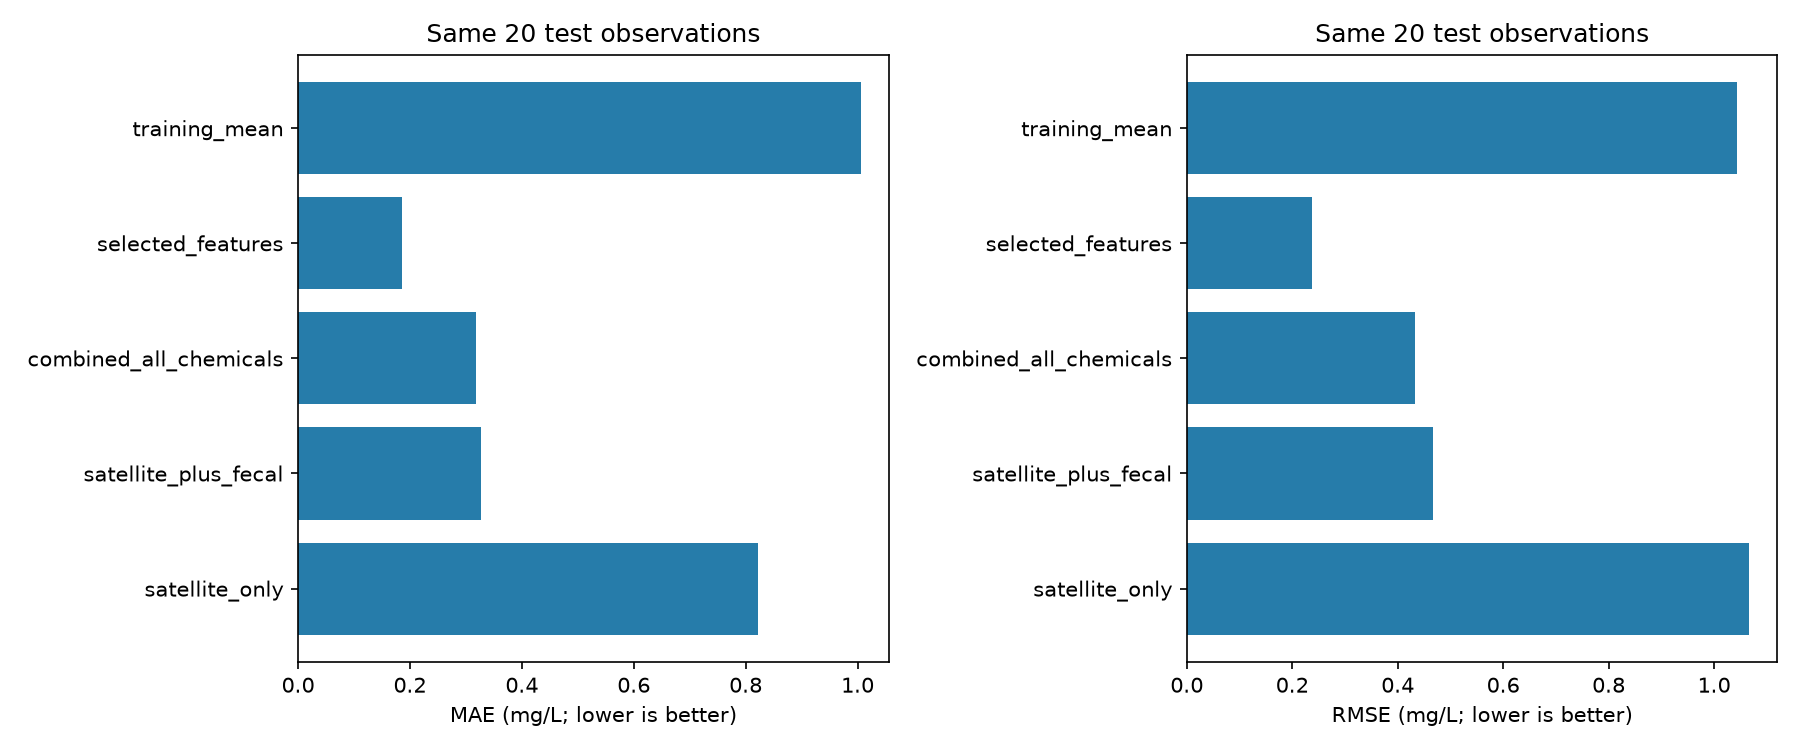

,sample_date,actual_bod_mg_l,satellite_only_bod_mg_l,combined_all_chemicals_bod_mg_l,selected_features_bod_mg_l
0,2021-09-15,3.7,2.218,3.079,3.389
1,2021-09-28,1.2,1.758,1.134,1.290
2,2021-10-04,3.5,1.104,2.816,3.269
3,2021-10-11,1.4,1.525,1.486,1.579
4,2021-10-12,1.3,1.978,1.129,1.192
5,2021-10-18,3.4,2.643,2.757,3.522


In [5]:
metrics = pd.read_csv(DEMOS / 'metrics.csv')
comparison = pd.read_csv(DEMOS / 'test_predictions.csv')
assert len(comparison) == 20 and metrics.n.eq(20).all()
display(metrics[['model', 'input_count', 'n', 'mae', 'rmse', 'r2']])
display(Image(filename=str(DEMOS / 'model_comparison.png')))
display(comparison[['sample_date', 'actual_bod_mg_l', 'satellite_only_bod_mg_l',
                    'combined_all_chemicals_bod_mg_l', 'selected_features_bod_mg_l']].head(6))


**What happened:** adding ground readings lowered average error on these cases. Satellite-only remains useful when ground readings are unavailable. The combined model's better result cannot be used without supplying its ground inputs.

These test events have been examined in earlier experiments. This is an exploratory demonstration, not an untouched final validation.


## 4. Feature selection

Inside the 80 training observations, 60 rank/train candidate inputs and 20 validate them. Twelve candidates compare top 3/5/10 bands with top 0/1/2/3 ground readings. The outer 20 test answers never choose the features. The chosen model is refitted using the outer 80 training cases.


Selected inputs: ground_fecal_coliform, satellite_B8A, satellite_B8, satellite_B11


,feature,modality,score,selected
0,ground_fecal_coliform,ground,0.856,True
1,ground_ph,ground,0.735,False
2,satellite_B8A,satellite,0.550,True
3,satellite_B8,satellite,0.546,True
4,satellite_B11,satellite,0.536,True
5,satellite_B7,satellite,0.529,False
6,satellite_B6,satellite,0.507,False
7,satellite_B12,satellite,0.486,False
8,ground_dissolved_oxygen,ground,0.457,False
9,satellite_B5,satellite,0.364,False


,candidate,input_count,validation_mae,selected
1,top3_bands_top1_ground,4,0.357,True
11,top10_bands_top3_ground,13,0.362,False
5,top5_bands_top1_ground,6,0.373,False
9,top10_bands_top1_ground,11,0.402,False
2,top3_bands_top2_ground,5,0.423,False
3,top3_bands_top3_ground,6,0.436,False
6,top5_bands_top2_ground,7,0.440,False
10,top10_bands_top2_ground,12,0.446,False
7,top5_bands_top3_ground,8,0.458,False
8,top10_bands_top0_ground,10,0.697,False


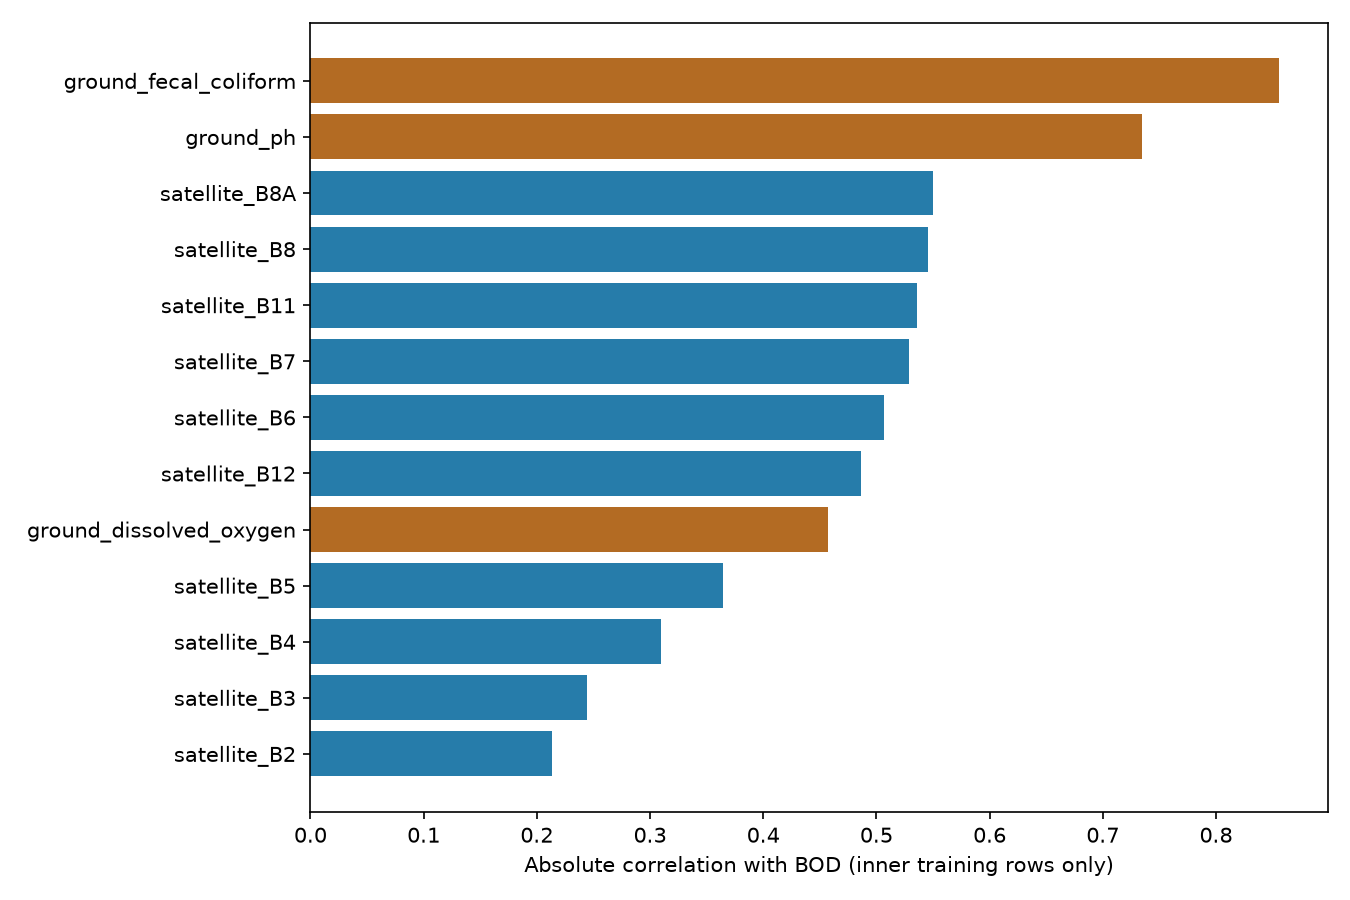

In [6]:
ranking = pd.read_csv(DEMOS / 'feature_ranking.csv')
candidates = pd.read_csv(DEMOS / 'feature_candidates.csv')
selected = ranking.loc[ranking.selected, 'feature'].tolist()
print('Selected inputs:', ', '.join(selected))
display(ranking[['feature', 'modality', 'score', 'selected']])
display(candidates[['candidate', 'input_count', 'validation_mae', 'selected']].sort_values('validation_mae'))
display(Image(filename=str(DEMOS / 'feature_ranking.png')))


The selected model kept **B8, B8A, B11 and fecal coliform**. Ranking pH or DO highly does not guarantee that including it improves the smaller model. Feature selection is based on this small dataset, not a universal statement about river chemistry.


## 5. SHAP: why did the combined model predict that number?

Actual Kernel SHAP explains three fixed test examples, one per station, relative to a background sampled only from training data. Red contributions raise predicted BOD; blue contributions lower it. The full chart explains the all-chemical combined model, not the satellite-only or selected-input model.

Contributions explain model behavior and are reference-dependent. They do not establish physical causes. Correlated bands can make individual contributions harder to interpret.


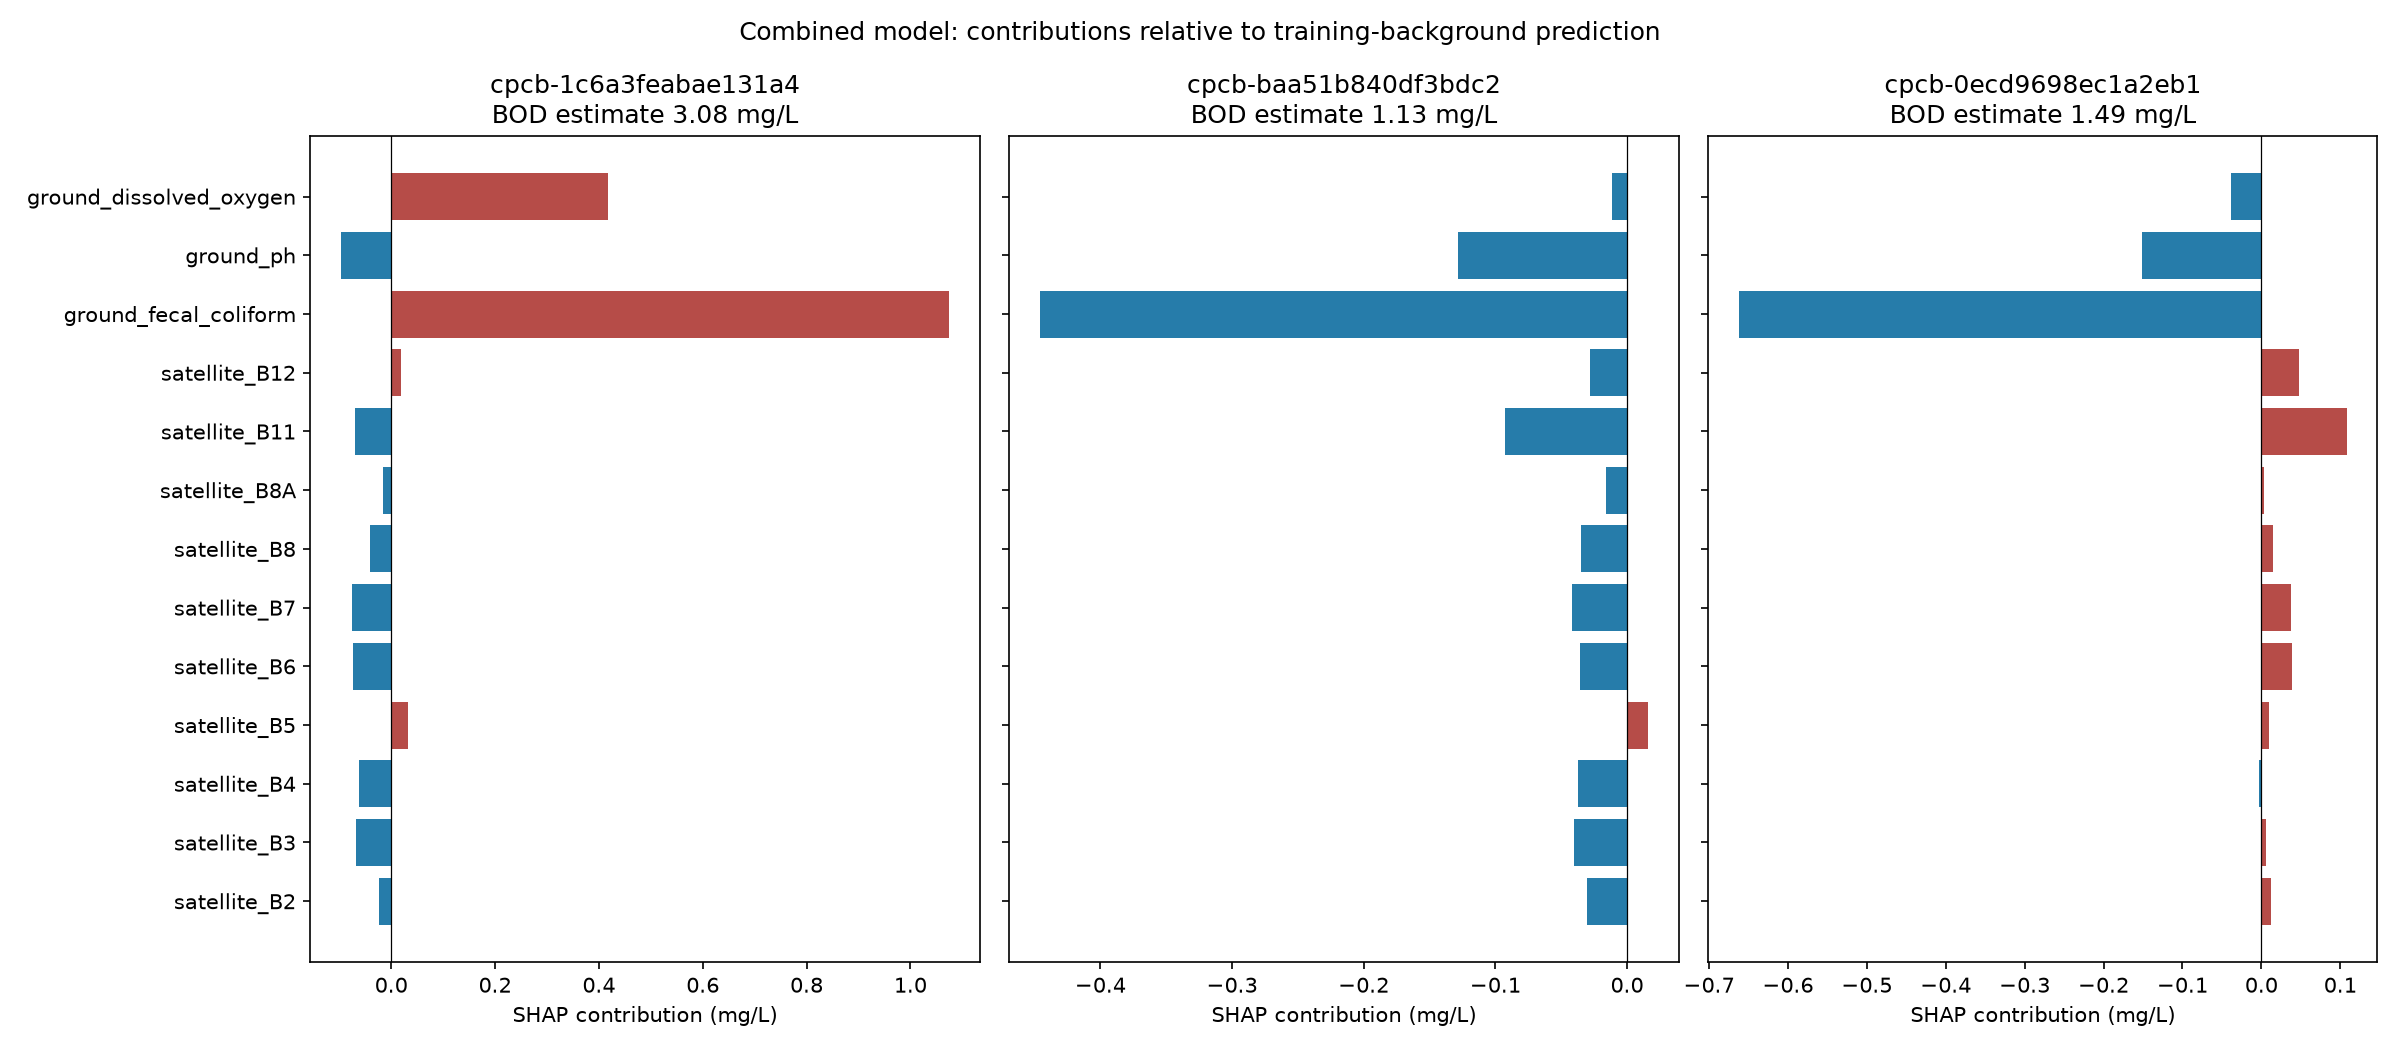

,station_name,predicted_bod_mg_l,reference_bod_mg_l,satellite_contribution_mg_l,ground_contribution_mg_l
0,GANGA AT VARANASI D/S (MALVIYA BRIDGE) U.P,3.079,2.061,-0.378,1.396
1,RIVER GANGA AT MADHYA GANGA BARRAGE BIJNOR,1.134,2.061,-0.341,-0.586
2,GANGA U/S ANOOPSHAHAR,1.486,2.061,0.276,-0.852


Reference + satellite contributions + ground contributions reconstruct each estimate.


In [7]:
explanations = pd.read_csv(DEMOS / 'shap_explanations.csv')
display(Image(filename=str(DEMOS / 'shap_examples.png')))
display(explanations[['station_name', 'predicted_bod_mg_l', 'reference_bod_mg_l',
                      'satellite_contribution_mg_l', 'ground_contribution_mg_l']])
reconstructed = (explanations.reference_bod_mg_l + explanations.satellite_contribution_mg_l
                 + explanations.ground_contribution_mg_l)
np.testing.assert_allclose(reconstructed, explanations.predicted_bod_mg_l, atol=1e-6)
print('Reference + satellite contributions + ground contributions reconstruct each estimate.')


## 6. Small experimental network: gate, constraint and station adversary

A separate two-branch PyTorch model has independent switches:

- **Gate:** learn satellite/ground weights from the date difference.
- **Constraint:** penalize negative raw BOD during training.
- **Station adversary:** use a station classifier with reversed gradients to encourage less station-specific representations.

These are modest mechanism demonstrations. The constraint is not a full physics-equation PINN. Station regularization is not proven transfer to a foreign river. The original scikit-learn predictor stays preserved.


,model,epochs,n,mae,rmse,r2
0,baseline,142,20,0.321,0.439,0.818
1,gate_only,127,20,0.280,0.363,0.876
2,constraint_only,142,20,0.322,0.439,0.818
3,station_adversarial_only,141,20,0.325,0.442,0.816
4,all_components,126,20,0.283,0.365,0.874
5,training_mean,0,20,1.005,1.044,-0.029


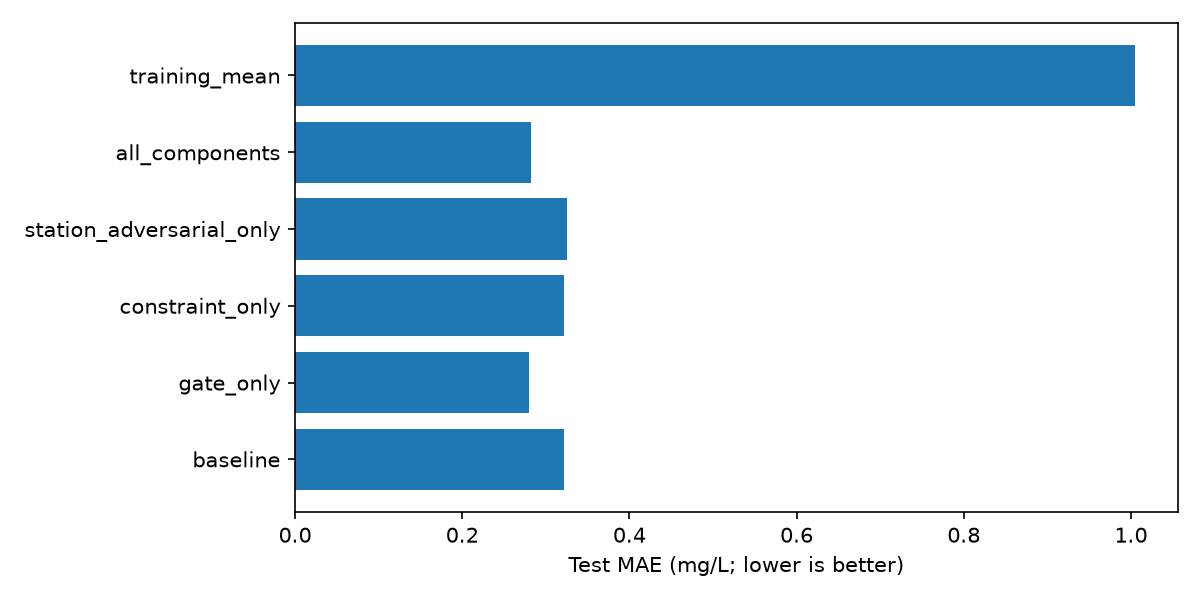

Baseline, each switch alone, and all three together were evaluated on the same 20 cases.


In [8]:
experimental = read_json(EXPERIMENT / 'run.json')
experimental_metrics = pd.read_csv(EXPERIMENT / 'metrics.csv')
display(experimental_metrics[['model', 'epochs', 'n', 'mae', 'rmse', 'r2']])
display(Image(filename=str(EXPERIMENT / 'comparison.png')))
print('Baseline, each switch alone, and all three together were evaluated on the same 20 cases.')


### Gate weights

The chart holds one example's readings constant and changes only the satellite–sampling gap. With the gate off, branch weights stay at 0.5. The learned gate reduced satellite weight as the gap increased in this run. These weights are not confidence percentages or SHAP contributions.


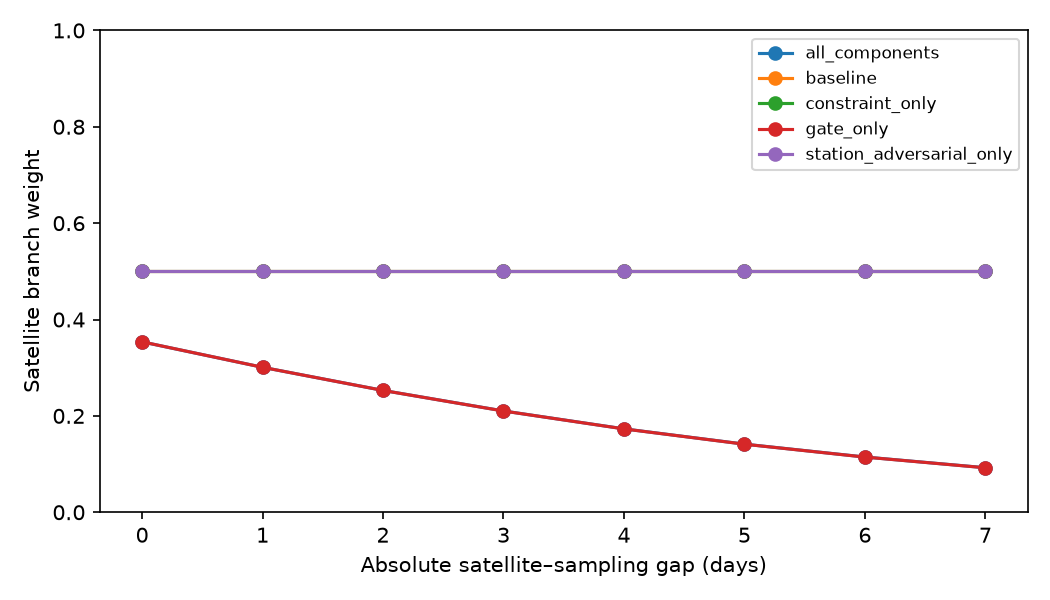

,absolute_gap_days,satellite_weight,ground_weight,predicted_bod_mg_l
32,0,0.354,0.646,3.016
33,1,0.301,0.699,3.155
34,2,0.253,0.747,3.264
35,3,0.210,0.790,3.348
36,4,0.173,0.827,3.412
37,5,0.141,0.859,3.462
38,6,0.115,0.885,3.499
39,7,0.092,0.908,3.528


In [9]:
display(Image(filename=str(EXPERIMENT / 'gate_weights.png')))
sweep = pd.read_csv(EXPERIMENT / 'gate_sweep.csv')
display(sweep[sweep.model.eq('all_components')][['absolute_gap_days', 'satellite_weight', 'ground_weight', 'predicted_bod_mg_l']])
np.testing.assert_allclose(sweep.satellite_weight + sweep.ground_weight, 1.0, atol=1e-6)


### Training constraint and station classifier

The saved loss histories show that the constraint was actually active and the classifier trained. A mechanism can run without improving accuracy. In particular, the classifier still identifies stations well: station invariance was not achieved.


,Variant,Gate,Constraint,Adversarial,Epochs with applied penalty,Station training accuracy
0,baseline,False,False,False,0,NaN
1,gate_only,True,False,False,0,NaN
2,constraint_only,False,True,False,29,NaN
3,station_adversarial_only,False,False,True,0,0.988
4,all_components,True,True,True,27,0.962


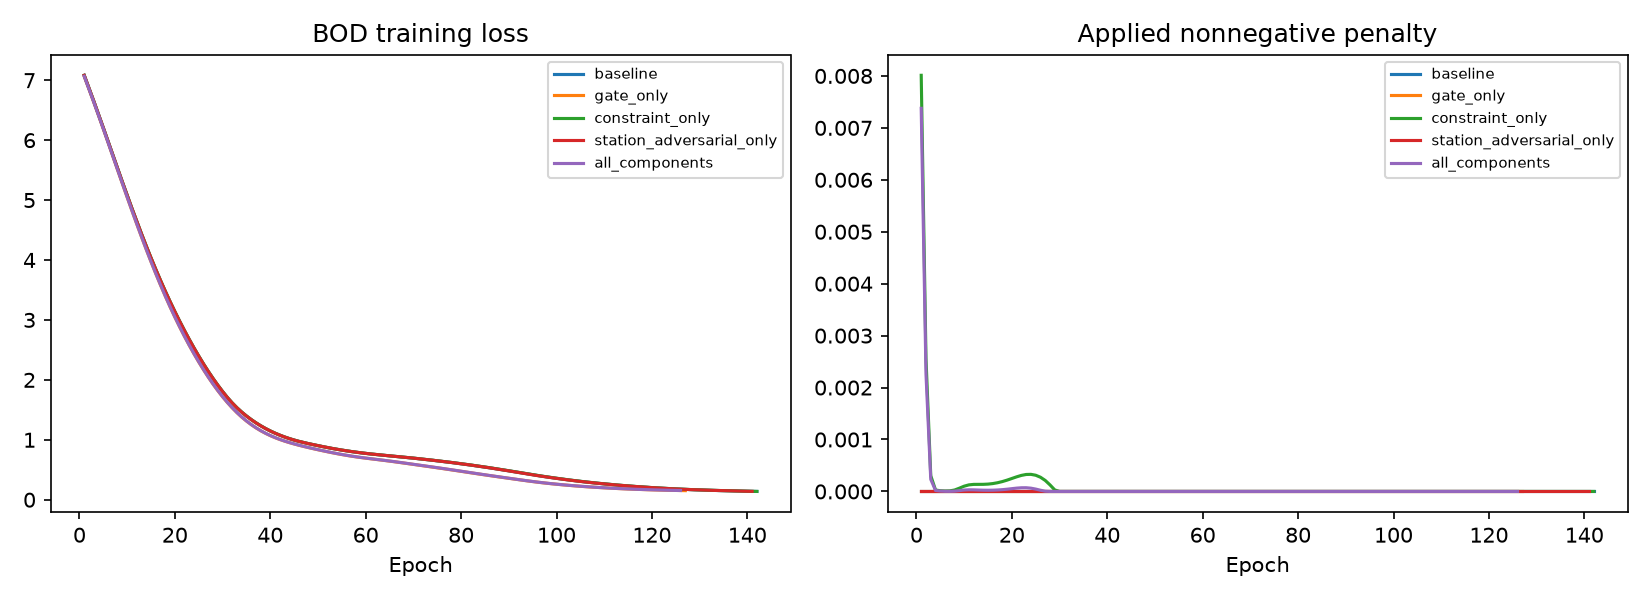

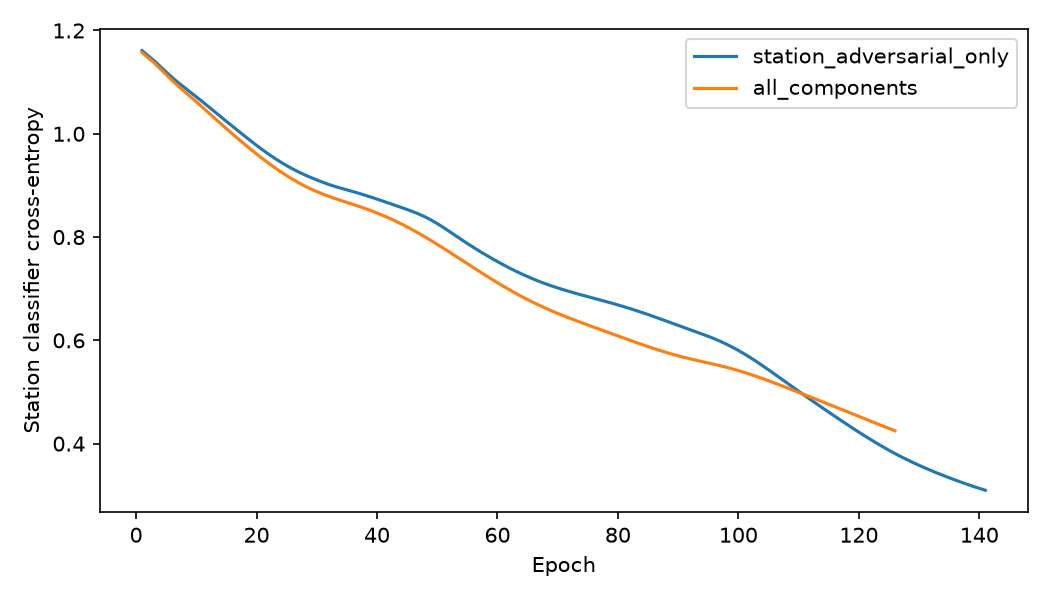

In [10]:
mechanisms = []
for name, result in experimental['variants'].items():
    mechanisms.append({'Variant': name, 'Gate': result['switches']['gate'],
                       'Constraint': result['switches']['constraint'],
                       'Adversarial': result['switches']['station_adversarial'],
                       'Epochs with applied penalty': result['epochs_with_constraint_penalty'],
                       'Station training accuracy': result['station_classifier_training_accuracy']})
display(pd.DataFrame(mechanisms))
display(Image(filename=str(EXPERIMENT / 'training_losses.png')))
display(Image(filename=str(EXPERIMENT / 'station_adversarial_loss.png')))


## 7. What can we demonstrate?

**Working:** real data matching, saved-model predictions, fair input comparison, training-only spectral/chemical feature selection, actual SHAP explanations, learned date-gap weights, a training penalty, and station-adversarial gradient reversal.

**Results are mixed:** combined inputs and selected features helped this sample; the gate helped the small experimental network; the constraint and adversarial-only variants did not improve their scores. All results, including ineffective variants, are retained.

**Scope:** three Ganga stations, 100 observations, BOD estimation. This does not establish overall water safety, future forecasting, an image CNN, broad unseen-river performance or a full physics-informed model. Source sampling/QC, coordinate/time and water-pixel assumptions remain documented.

The comparison models are separate experiments; no saved working model was automatically replaced.


In [11]:
assert {str(p.relative_to(ROOT)): sha(p) for p in model_paths} == original_model_hashes
assert sha(DATA / 'paired.csv') == provenance['output_sha256']
print('Demonstration completed: original models unchanged, dataset verified, predictions reproduced, SHAP sums verified, gate weights normalized.')


Demonstration completed: original models unchanged, dataset verified, predictions reproduced, SHAP sums verified, gate weights normalized.


## Reproduction and supporting documentation

- [Dataset sources and units](../docs/chemical_dataset.md)
- [Comparisons, feature selection and SHAP](../docs/straightforward_demonstrations.md)
- [Experimental mechanisms and on/off commands](../docs/experimental_network.md)
- [Saved satellite-only model](../docs/working_model.md)

To rerun experiments, follow those guides and use fresh output directories. This notebook reads their saved outputs so the presentation remains fast and independent of live satellite services.
